# 07 · Análisis del monitoreo, ética y resultado de negocio

Analiza la simulación de producción (8 lotes del 2015-06-20 al 2015-07-31) que ejecutó Kestra con `produccion_lotes.yml`:

1. **Monitoreo lote por lote** (secciones 6 y 7): desempeño, deriva, alertas y reentrenamientos.
2. **Ética operativa** (sección 8): desempeño por subgrupo, costo de cada error, criterios de retirada y supervisión humana.
3. **Resultado de negocio** (sección 9): costo de turnos mal asignados del modelo frente a la regla del gerente y a no hacer nada.

Fuentes (Snowflake, esquema `OPERACION`): `PREDICCIONES` (las registra la API), `VENTAS_REALES` (llegan al lote siguiente),
`LOTES_SIMULACION` (features y deriva inducida), `MONITOREO` y `ALERTAS` (flujo `monitoreo`).

**Deriva inducida en los lotes 6, 7 y 8** (escenario de prueba): abre un competidor cerca de las tiendas tipo "a";
su `competition_distance_m` se multiplica por 0,1 y sus ventas reales por 0,8.

In [1]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from monitoreo.alertas import UMBRAL_WAPE
from src.datos import conectar
from src.pipeline import BOOLEANAS, FEATURES, configurar_mlflow, costo_turnos, wape

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
LOTES_DERIVA = [6, 7, 8]


def consultar(sql: str) -> pd.DataFrame:
    with conectar("OPERACION") as conn:
        df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = df.columns.str.lower()
    return df

In [2]:
# Cada prediccion de la simulacion con su venta real y los atributos de la tienda
datos = consultar("""
    SELECT TRY_TO_NUMBER(p.LOTE) AS LOTE, p.STORE_ID, p.FECHA,
           p.VENTAS_PRONOSTICADAS AS PRED_MODELO, p.VENTAS_REGLA AS PRED_REGLA,
           p.DECISION, p.VERSION_MODELO, p.RESPALDO,
           v.SALES AS VENTAS, v.ALTERADO,
           l.STORE_TYPE, l.ASSORTMENT, l.IS_PROMO, l.SALES_MEAN_LAG42_28D AS VENTA_HABITUAL
    FROM PREDICCIONES p
    JOIN VENTAS_REALES v ON v.LOTE = TRY_TO_NUMBER(p.LOTE) AND v.STORE_ID = p.STORE_ID AND v.FECHA = p.FECHA
    JOIN LOTES_SIMULACION l ON l.LOTE = v.LOTE AND l.STORE_ID = v.STORE_ID AND l.SALES_DATE = v.FECHA
""")
monitoreo = consultar("SELECT LOTE, TIPO, METRICA, VARIABLE, VALOR, TEXTO FROM MONITOREO")
alertas = consultar("SELECT LOTE, SEVERIDAD, TIPO, METRICA, VARIABLE, VALOR, UMBRAL, DESTINATARIO, ACCION "
                    "FROM ALERTAS ORDER BY LOTE")

print(f"{len(datos)} tienda-dia con prediccion y venta real")
datos.groupby("lote").agg(desde=("fecha", "min"), hasta=("fecha", "max"), filas=("store_id", "size"),
                          version_modelo=("version_modelo", "first"), filas_alteradas=("alterado", "sum"),
                          respaldo=("respaldo", "sum"))

40282 tienda-dia con prediccion y venta real


,desde,hasta,filas,version_modelo,filas_alteradas,respaldo
lote,,,,,,
1,2015-06-20,2015-06-24,4488,1,0,0
2,2015-06-25,2015-06-29,4491,1,0,0
3,2015-06-30,2015-07-04,5572,1,0,0
4,2015-07-05,2015-07-09,4489,1,0,0
5,2015-07-10,2015-07-14,4485,1,0,0
6,2015-07-15,2015-07-19,4482,1,2410,0
7,2015-07-20,2015-07-25,6678,1,3600,0
8,2015-07-26,2015-07-31,5597,4,3012,0


## 1. Monitoreo lote por lote

In [3]:
desempeno = (monitoreo[monitoreo["tipo"] == "desempeno"]
             .pivot_table(index="lote", columns="metrica", values="valor"))
desempeno["version"] = datos.groupby("lote")["version_modelo"].first()
desempeno["diagnostico"] = monitoreo[monitoreo["metrica"] == "diagnostico"].set_index("lote")["texto"]
desempeno["alertas"] = alertas.groupby("lote").size().reindex(desempeno.index, fill_value=0)
desempeno[["version", "wape_modelo", "wape_regla", "costo_modelo_k2", "costo_regla_k2", "diagnostico", "alertas"]]

metrica,version,wape_modelo,wape_regla,costo_modelo_k2,costo_regla_k2,diagnostico,alertas
lote,,,,,,,
1,1,0.0788,0.2512,0.1260,0.2558,Sin deriva,0
2,1,0.0742,0.2136,0.1100,0.2858,Sin deriva,0
3,1,0.1258,0.1622,0.1530,0.2572,Deriva conceptual,1
4,1,0.0861,0.2138,0.1277,0.2211,Sin deriva,0
5,1,0.0808,0.1412,0.1051,0.2129,Sin deriva,0
6,1,0.1740,0.1687,0.1890,0.1949,Deriva de datos con impacto,4
7,1,0.1513,0.3970,0.1829,0.4012,Deriva de datos con impacto,3
8,4,0.1553,0.1541,0.1773,0.2301,Deriva de datos con impacto,4


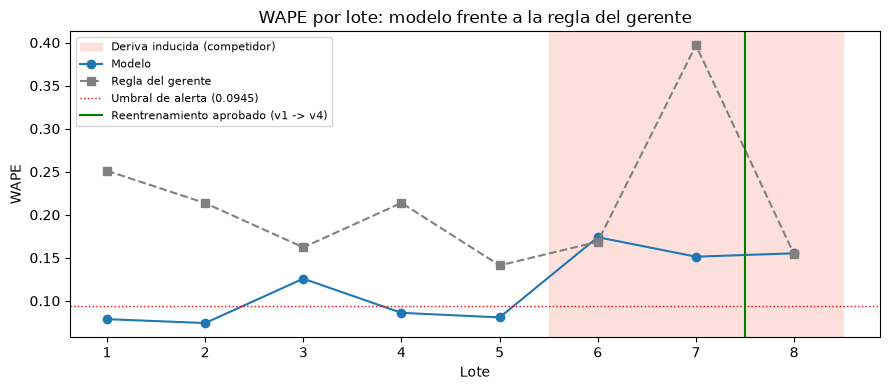

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(5.5, 8.5, color="#fde0dc", label="Deriva inducida (competidor)")
ax.plot(desempeno.index, desempeno["wape_modelo"], "o-", label="Modelo")
ax.plot(desempeno.index, desempeno["wape_regla"], "s--", color="gray", label="Regla del gerente")
ax.axhline(UMBRAL_WAPE, color="red", lw=1, ls=":", label=f"Umbral de alerta ({UMBRAL_WAPE})")
ax.axvline(7.5, color="green", lw=1.5, label="Reentrenamiento aprobado (v1 -> v4)")
ax.set(xlabel="Lote", ylabel="WAPE", title="WAPE por lote: modelo frente a la regla del gerente")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("../docs/img/wape_por_lote.png", dpi=150)
plt.show()

In [5]:
# PSI de cada variable frente al entrenamiento (solo las de uso 'alerta' disparan alertas)
psi = monitoreo[monitoreo["metrica"] == "psi"]
tabla_psi = psi.pivot_table(index=["texto", "variable"], columns="lote", values="valor")
tabla_psi.index.names = ["uso", "variable"]
tabla_psi.style.format("{:.3f}").background_gradient(cmap="Reds", vmin=0, vmax=0.5)

In [6]:
alertas.groupby(["lote", "severidad", "metrica"]).size().unstack(["severidad", "metrica"], fill_value=0)

severidad        Alta                   Critica              Media
metrica   wape_modelo psi modelo_peor_que_regla pct_fuera_de_rango
lote                                                              
3                   1   0                     0                  0
6                   1   1                     1                  1
7                   1   1                     0                  1
8                   1   1                     1                  1

### Por qué la regla del gerente falla en algunos lotes

La regla promedia las ventas del mismo día de la semana en 4 semanas, que mezclan días con y sin promoción.
Se compara su error con la proporción de días con promoción en cada lote.

In [7]:
promo = datos.groupby("lote").agg(pct_dias_con_promo=("is_promo", "mean"))
promo["wape_regla"] = desempeno["wape_regla"]
promo["wape_modelo"] = desempeno["wape_modelo"]
promo["tasa_reducir_turnos"] = datos.groupby("lote")["decision"].apply(lambda d: (d == "reducir_turnos").mean())
promo

,pct_dias_con_promo,wape_regla,wape_modelo,tasa_reducir_turnos
lote,,,,
1,0.0000,0.2512,0.0788,0.7377
2,0.2483,0.2136,0.0742,0.3923
3,0.8001,0.1622,0.1258,0.0014
4,0.0000,0.2138,0.0861,0.5562
5,0.4963,0.1412,0.0808,0.1855
6,0.7445,0.1687,0.1740,0.0120
7,0.0000,0.3970,0.1513,0.7442
8,0.9943,0.1541,0.1553,0.0025


## 2. Ética operativa (sección 8)

### 2.1 Desempeño por subgrupo

Subgrupos: **tipo de tienda** (a, b, c, d) y **surtido** (a = básico, b = extra, c = extendido). Se analizan los lotes
1 a 5, sin deriva, para no confundir un sesgo del modelo con el competidor simulado; los lotes 6 a 8 se muestran aparte.

In [8]:
def resumen(g: pd.DataFrame) -> pd.Series:
    tasas = g["decision"].value_counts(normalize=True)
    return pd.Series({
        "tiendas": g["store_id"].nunique(),
        "tienda_dia": len(g),
        "wape_modelo": wape(g["ventas"], g["pred_modelo"]),
        "wape_regla": wape(g["ventas"], g["pred_regla"]),
        "costo_modelo": costo_turnos(g["ventas"], g["pred_modelo"]),
        "costo_regla": costo_turnos(g["ventas"], g["pred_regla"]),
        "reforzar": tasas.get("reforzar_turnos", 0.0),
        "mantener": tasas.get("mantener_plan", 0.0),
        "reducir": tasas.get("reducir_turnos", 0.0),
    })


normales = datos[~datos["lote"].isin(LOTES_DERIVA)]
general = resumen(normales).rename("todas")
por_tipo = pd.concat([normales.groupby("store_type").apply(resumen), general.to_frame().T])
por_tipo["wape_vs_general"] = por_tipo["wape_modelo"] / general["wape_modelo"]
por_tipo

,tiendas,tienda_dia,wape_modelo,wape_regla,costo_modelo,costo_regla,reforzar,mantener,reducir,wape_vs_general
a,602.0,12672.0,0.0918,0.1900,0.1266,0.2470,0.1617,0.4883,0.3500,0.9964
b,17.0,425.0,0.0736,0.1107,0.1219,0.1554,0.0659,0.8259,0.1082,0.7990
c,148.0,3108.0,0.0924,0.1950,0.1291,0.2498,0.1766,0.4263,0.3970,1.0026
d,348.0,7320.0,0.0943,0.1977,0.1242,0.2544,0.2026,0.4292,0.3682,1.0235
todas,1115.0,23525.0,0.0922,0.1908,0.1260,0.2471,0.1747,0.4678,0.3575,1.0000


In [9]:
por_surtido = normales.groupby("assortment").apply(resumen)
por_surtido["wape_vs_general"] = por_surtido["wape_modelo"] / general["wape_modelo"]
por_surtido

,tiendas,tienda_dia,wape_modelo,wape_regla,costo_modelo,costo_regla,reforzar,mantener,reducir,wape_vs_general
assortment,,,,,,,,,,
a,593.0,12477.0,0.0929,0.1965,0.1250,0.2520,0.1725,0.4528,0.3747,1.0080
b,9.0,225.0,0.0731,0.0988,0.1142,0.1387,0.0489,0.9244,0.0267,0.7930
c,513.0,10823.0,0.0919,0.1875,0.1275,0.2451,0.1798,0.4757,0.3445,0.9976


In [10]:
# Lotes 6 a 8: el competidor afecta solo a las tiendas tipo a
deriva = datos[datos["lote"].isin(LOTES_DERIVA)]
deriva.groupby("store_type").apply(resumen)

,tiendas,tienda_dia,wape_modelo,wape_regla,costo_modelo,costo_regla,reforzar,mantener,reducir
store_type,,,,,,,,,
a,601.0,9022.0,0.2421,0.3222,0.2474,0.3305,0.1347,0.5515,0.3138
b,17.0,289.0,0.0802,0.1128,0.1278,0.1446,0.0484,0.7716,0.1799
c,148.0,2220.0,0.0878,0.1706,0.1378,0.2460,0.1766,0.5167,0.3068
d,348.0,5226.0,0.0834,0.1635,0.1177,0.2291,0.2101,0.5078,0.2821


### 2.2 Costo de cada error

| Error | Qué pasa en la tienda | Quién lo asume |
|---|---|---|
| **Sobreestimación** (pronóstico > venta) | Sobra personal en el turno | La empresa: costo de horas pagadas sin trabajo (área de operaciones y finanzas) |
| **Subestimación** (pronóstico < venta) | Faltan cajeros y reponedores | Los **empleados** (sobrecarga) y los **clientes** (filas, quiebres de stock); la tienda pierde ventas |

Por eso el costo de turnos pesa la subestimación con k = 2. Se mide qué parte del error es de cada tipo.

In [11]:
err = datos.assign(error=datos["pred_modelo"] - datos["ventas"],
                   periodo=np.where(datos["lote"].isin(LOTES_DERIVA), "lotes 6-8 (deriva)", "lotes 1-5"))
err["tipo_error"] = np.where(err["error"] > 0, "sobreestimacion", "subestimacion")
costo_error = (err.groupby(["periodo", "tipo_error"])
               .agg(casos=("error", "size"), error_absoluto=("error", lambda e: e.abs().sum())))
costo_error["pct_casos"] = costo_error["casos"] / costo_error.groupby(level=0)["casos"].transform("sum")
costo_error["pct_error"] = costo_error["error_absoluto"] / costo_error.groupby(level=0)["error_absoluto"].transform("sum")
costo_error

casos  error_absoluto  pct_casos  \
periodo            tipo_error                                          
lotes 1-5          sobreestimacion  13943      9.4792e+06     0.5927   
                   subestimacion     9582      5.5114e+06     0.4073   
lotes 6-8 (deriva) sobreestimacion  12818      1.4377e+07     0.7649   
                   subestimacion     3939      2.4670e+06     0.2351   

                                    pct_error  
periodo            tipo_error                  
lotes 1-5          sobreestimacion     0.6323  
                   subestimacion       0.3677  
lotes 6-8 (deriva) sobreestimacion     0.8535  
                   subestimacion       0.1465

In [12]:
# Subestimacion por tipo de tienda: donde se concentra el costo que asumen empleados y clientes
(err[err["periodo"] == "lotes 1-5"]
 .groupby("store_type")
 .apply(lambda g: pd.Series({
     "pct_subestimacion": (g["tipo_error"] == "subestimacion").mean(),
     "subestimacion_media_eur": g.loc[g["error"] < 0, "error"].abs().mean(),
 })))

,pct_subestimacion,subestimacion_media_eur
store_type,,
a,0.4034,588.5099
b,0.6188,847.6503
c,0.4279,582.3147
d,0.3930,523.3035


### 2.3 Criterios de retirada

| # | Condición observable | Métrica y umbral | Respuesta | Decide |
|---|---|---|---|---|
| 1 | El modelo cuesta más que la regla | Costo de turnos del modelo > costo de la regla durante **2 lotes seguidos** | Activar `MODO_RESPALDO=true`: la API usa la regla del gerente | Jefe de operaciones de tiendas, con el equipo de datos |
| 2 | El reentrenamiento no corrige la caída | WAPE > 0,0945 durante **2 lotes seguidos después de** un reentrenamiento aprobado | Escalar al equipo de datos: revisar features y datos del nuevo régimen; si además se cumple el criterio 1, respaldo | Equipo de datos |
| 3 | El modelo perjudica a un subgrupo | WAPE de un tipo de tienda > **2 veces su propio WAPE de referencia** (lotes 1-5, sin deriva) durante **2 lotes seguidos** | Revisión del subgrupo por el equipo de datos y aviso a los gerentes de esas tiendas para que apliquen su juicio sobre eventos locales. Solo se pasa a la regla para ese subgrupo si además su costo de turnos queda peor que el de la regla | Equipo de datos y gerentes de esas tiendas |
| 4 | El servicio no responde con el modelo | % de predicciones en respaldo > 0 o tasa de errores 5xx > 1 % en un lote | Revisar la API; si no se resuelve antes del siguiente lote, respaldo | Equipo de plataforma |

El criterio 3 se definió primero contra el WAPE **general**, pero así no detectaba al competidor: las tiendas tipo "a"
son el 54 % de los datos y arrastran el promedio con ellas (cociente máximo 1,57 en el lote 6, aunque su WAPE pasó de
0,092 a 0,242). Por eso cada subgrupo se compara con **su propio** nivel de referencia.

Se evalúan sobre la simulación:

In [13]:
lotes = desempeno.index
criterios = pd.DataFrame(index=lotes)
peor_costo = desempeno["costo_modelo_k2"] > desempeno["costo_regla_k2"]
criterios["c1_costo_peor_que_regla"] = peor_costo
criterios["c1_se_cumple"] = peor_costo & peor_costo.shift(1, fill_value=False)

sobre_umbral = desempeno["wape_modelo"] > UMBRAL_WAPE
version = desempeno["version"].astype(int)
despues_reentreno = version != version.iloc[0]
criterios["c2_wape_sobre_umbral_tras_reentreno"] = sobre_umbral & despues_reentreno
criterios["c2_se_cumple"] = criterios["c2_wape_sobre_umbral_tras_reentreno"] & criterios["c2_wape_sobre_umbral_tras_reentreno"].shift(1, fill_value=False)

wape_tipo = datos.groupby(["lote", "store_type"]).apply(lambda g: wape(g["ventas"], g["pred_modelo"])).unstack()
referencia = wape_tipo.loc[[l for l in wape_tipo.index if l not in LOTES_DERIVA]].mean()  # nivel propio sin deriva
ratio = wape_tipo.div(referencia, axis=1)
criterios["c3_max_ratio_subgrupo"] = ratio.max(axis=1)
criterios["c3_tipo"] = ratio.idxmax(axis=1)
excede = ratio > 2
criterios["c3_se_cumple"] = (excede & excede.shift(1, fill_value=False)).any(axis=1)
# Respuesta del criterio 3: pasar el subgrupo a la regla solo si la regla le cuesta menos
costo_sub = datos.groupby(["lote", "store_type"]).apply(
    lambda g: costo_turnos(g["ventas"], g["pred_modelo"]) < costo_turnos(g["ventas"], g["pred_regla"])).unstack()
criterios["c3_modelo_mejor_que_regla_en_ese_tipo"] = [costo_sub.loc[l, t] for l, t in criterios["c3_tipo"].items()]

sistema = monitoreo[monitoreo["tipo"].isin(["sistema", "modelo"])].pivot_table(index="lote", columns="metrica", values="valor")
criterios["c4_pct_respaldo"] = sistema["pct_respaldo"]
criterios["c4_tasa_5xx"] = sistema["tasa_5xx"]
criterios

,c1_costo_peor_que_regla,c1_se_cumple,c2_wape_sobre_umbral_tras_reentreno,c2_se_cumple,c3_max_ratio_subgrupo,c3_tipo,c3_se_cumple,c3_modelo_mejor_que_regla_en_ese_tipo,c4_pct_respaldo,c4_tasa_5xx
lote,,,,,,,,,,
1,False,False,False,False,0.9102,a,False,True,0.0,0.0
2,False,False,False,False,0.9043,c,False,True,0.0,0.0
3,False,False,False,False,1.5028,d,False,True,0.0,0.0
4,False,False,False,False,1.0144,b,False,True,0.0,0.0
5,False,False,False,False,1.0495,b,False,True,0.0,0.0
6,False,False,False,False,3.0690,a,False,False,0.0,0.0
7,False,False,False,False,2.5017,a,True,True,0.0,0.0
8,False,False,True,False,2.6682,a,True,False,0.0,0.0


**Lectura.** El criterio 3 se cumple en los lotes 7 y 8 (las tiendas tipo "a" llegan a 3 veces su WAPE de referencia).
La respuesta se decide lote por lote. En el lote 7 el modelo seguía costando menos que la regla en esas tiendas (semana sin
promoción, donde la regla falla), así que solo se revisa. En el lote 8 la regla costaba menos, así que esas tiendas pasan a la
regla. El total de los lotes 6 a 8 (modelo 0,247 frente a regla 0,331) escondía que la regla fue mejor en 2 de los 3 lotes:
la respuesta debe evaluarse lote por lote y no con el agregado.

Efecto de aplicar la respuesta en el lote 8 (tiendas tipo "a" con la regla, el resto con el modelo):

In [14]:
g8 = datos[datos["lote"] == 8]
mixto = np.where(g8["store_type"] == "a", g8["pred_regla"], g8["pred_modelo"])
pd.DataFrame({"costo_turnos_lote_8": {
    "modelo v4 en todas las tiendas": costo_turnos(g8["ventas"], g8["pred_modelo"]),
    "criterio 3 aplicado (tipo a con la regla)": costo_turnos(g8["ventas"], mixto),
    "regla en todas las tiendas": costo_turnos(g8["ventas"], g8["pred_regla"]),
}})

,costo_turnos_lote_8
modelo v4 en todas las tiendas,0.1773
criterio 3 aplicado (tipo a con la regla),0.1522
regla en todas las tiendas,0.2301


Aplicar la respuesta del criterio 3 en el lote 8 habría bajado el costo de turnos de 0,1773 a **0,1522** (−14 %), mejor que usar solo el modelo y que usar solo la regla (0,2301).

### 2.4 Interruptor de respaldo

La API lee `MODO_RESPALDO` al arrancar. Con `MODO_RESPALDO=true` responde con la regla del gerente,
`"respaldo": true` y `"modelo": "regla_gerente"`. Demostración (PowerShell, desde `proyecto_final`):

```powershell
$env:MODO_RESPALDO = "true";  docker compose up -d api
curl.exe http://localhost:8000/salud
curl.exe -X POST http://localhost:8000/predecir -H "Content-Type: application/json" --data "@api/ejemplo_solicitud.json"
$env:MODO_RESPALDO = "false"; docker compose up -d api
```

Además, `tests/test_contrato.py::test_respaldo_si_el_modelo_no_carga` verifica en CI que, si el modelo no carga,
la API responde con la regla.

### 2.5 Supervisión humana

En el PSet 1 el juicio humano era: *el gerente revisa el pronóstico y puede ajustarlo por eventos locales que el modelo no conoce.*
Se mantiene, pero se precisa con lo observado en la simulación:

1. **Confirmar las reducciones grandes.** Cuando el modelo sugiere reducir turnos más de un 15 %, el gerente lo confirma antes de aplicarlo:
   la subestimación la pagan los empleados (sobrecarga) y los clientes (filas), y en las tiendas tipo "b" es más frecuente
   (62 % de sus errores, 848 € en promedio, frente a cerca del 40 % en el resto).
2. **Reportar los eventos locales.** El gerente registra los eventos que conoce, como la apertura de un competidor.
   En la simulación el monitoreo tardó 2 lotes en detectar al competidor (alerta de WAPE en los lotes 6 y 7);
   un gerente lo sabe desde el primer día, y su reporte permite adelantar la revisión del modelo.

## 3. Resultado de negocio (sección 9)

Métrica de negocio: **costo de turnos mal asignados** (k = 2), el error del pronóstico expresado como fracción de
las ventas, con la subestimación al doble. Se compara contra:

- **Línea base de negocio:** la regla del gerente (promedio del mismo día de la semana en 4 semanas).
- **No hacer nada:** planificar cada día con la venta habitual de la tienda (promedio de 28 días, 42 días atrás),
  sin ajustar por día de la semana, promoción ni feriados.

In [15]:
negocio = datos.groupby("lote").apply(lambda g: pd.Series({
    "version": g["version_modelo"].iloc[0],
    "costo_modelo": costo_turnos(g["ventas"], g["pred_modelo"]),
    "costo_regla": costo_turnos(g["ventas"], g["pred_regla"]),
    "costo_no_hacer_nada": costo_turnos(g["ventas"], g["venta_habitual"]),
}))
negocio["ahorro_vs_regla"] = 1 - negocio["costo_modelo"] / negocio["costo_regla"]


def total(g):
    return pd.Series({
        "costo_modelo": costo_turnos(g["ventas"], g["pred_modelo"]),
        "costo_regla": costo_turnos(g["ventas"], g["pred_regla"]),
        "costo_no_hacer_nada": costo_turnos(g["ventas"], g["venta_habitual"]),
    })


totales = pd.DataFrame({
    "lotes 1-5 (sin deriva)": total(normales),
    "lotes 6-8 (con deriva)": total(deriva),
    "los 8 lotes": total(datos),
}).T
totales["ahorro_vs_regla"] = 1 - totales["costo_modelo"] / totales["costo_regla"]
display(negocio)
totales

,version,costo_modelo,costo_regla,costo_no_hacer_nada,ahorro_vs_regla
lote,,,,,
1,1,0.1260,0.2558,0.3008,0.5075
2,1,0.1100,0.2858,0.4052,0.6153
3,1,0.1530,0.2572,0.2982,0.4051
4,1,0.1277,0.2211,0.2316,0.4223
5,1,0.1051,0.2129,0.3333,0.5065
6,1,0.1890,0.1949,0.2303,0.0299
7,1,0.1829,0.4012,0.4135,0.5441
8,4,0.1773,0.2301,0.2510,0.2296


,costo_modelo,costo_regla,costo_no_hacer_nada,ahorro_vs_regla
lotes 1-5 (sin deriva),0.1260,0.2471,0.3152,0.4899
lotes 6-8 (con deriva),0.1823,0.2771,0.2991,0.3421
los 8 lotes,0.1482,0.2589,0.3088,0.4275


In [16]:
# Efecto del reentrenamiento: el lote 8 con el champion anterior (v1) frente al que se uso (v4)
configurar_mlflow()
v1 = mlflow.sklearn.load_model("models:/rossmann-modelo/1")
columnas = ", ".join(["STORE_ID", "SALES_DATE", "SALES"] + [c.upper() for c in FEATURES])
lote8 = consultar(f"SELECT {columnas} FROM LOTES_SIMULACION WHERE LOTE = 8")
X8 = lote8[FEATURES].copy()
X8[BOOLEANAS] = X8[BOOLEANAS].astype(float)
pred_v1 = np.clip(v1.predict(X8), 0, None)

g8 = datos[datos["lote"] == 8]
efecto = pd.DataFrame({
    "wape": [wape(lote8["sales"], pred_v1), wape(g8["ventas"], g8["pred_modelo"]), wape(g8["ventas"], g8["pred_regla"])],
    "costo_turnos": [costo_turnos(lote8["sales"], pred_v1), costo_turnos(g8["ventas"], g8["pred_modelo"]),
                     costo_turnos(g8["ventas"], g8["pred_regla"])],
}, index=["v1 (sin reentrenar)", "v4 (reentrenado, en servicio)", "regla del gerente"])
efecto

,wape,costo_turnos
v1 (sin reentrenar),0.1767,0.1972
"v4 (reentrenado, en servicio)",0.1553,0.1773
regla del gerente,0.1541,0.2301


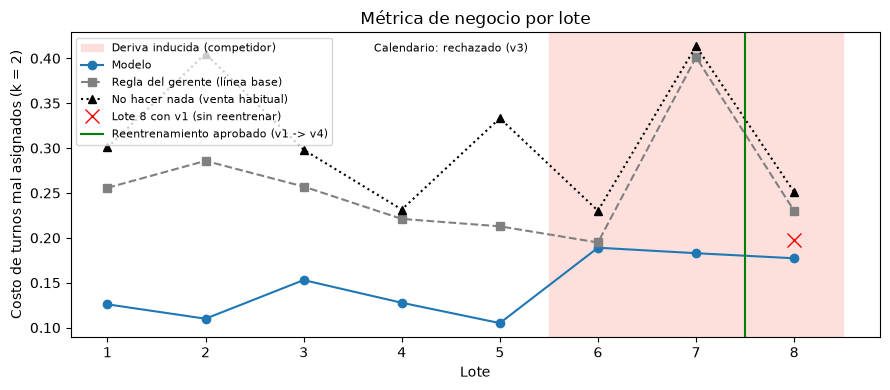

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(5.5, 8.5, color="#fde0dc", label="Deriva inducida (competidor)")
ax.plot(negocio.index, negocio["costo_modelo"], "o-", label="Modelo")
ax.plot(negocio.index, negocio["costo_regla"], "s--", color="gray", label="Regla del gerente (línea base)")
ax.plot(negocio.index, negocio["costo_no_hacer_nada"], "^:", color="black", label="No hacer nada (venta habitual)")
ax.plot(8, efecto.loc["v1 (sin reentrenar)", "costo_turnos"], "x", color="red", ms=10, label="Lote 8 con v1 (sin reentrenar)")
ax.axvline(7.5, color="green", lw=1.5, label="Reentrenamiento aprobado (v1 -> v4)")
ax.annotate("Calendario: rechazado (v3)", xy=(4.5, ax.get_ylim()[1] * 0.95), ha="center", fontsize=8)
ax.set(xlabel="Lote", ylabel="Costo de turnos mal asignados (k = 2)",
       title="Métrica de negocio por lote")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("../docs/img/negocio_por_lote.png", dpi=150)
plt.show()

### ¿Valió la pena actuar según la predicción?

**Sí.** Planificar los turnos con el modelo redujo el costo de turnos mal asignados en un **43 %** frente a la regla actual del gerente
(0,148 frente a 0,259) y en un **52 %** frente a no ajustar nada (0,309), en los 8 lotes. Ganó en cada uno de los 8 lotes,
incluso con el competidor simulado (34 % de ahorro en los lotes 6 a 8). El reentrenamiento aprobado recuperó parte del desempeño
perdido: en el lote 8 el costo bajó de 0,1972 con la v1 a 0,1773 con la v4 (−10 %).

**Con dos reservas.** La métrica supone que quedarse corto cuesta el doble que pasarse (k = 2) y que la dotación necesaria es
proporcional a las ventas. El beneficio en euros y en ventas por hora de personal debe confirmarse en un **piloto** con las horas
del sistema de asistencia de Rossmann.